# Randomized linear algebra: approximate the SVD

An exact SVD can be expensive for a large matrix. Randomized linear algebra uses a small random projection to find the subspace containing most of the important structure, then computes an SVD in that smaller subspace.

We will use this idea to build a rank-`k` approximation of an image, compare it with the exact truncated SVD, and measure accuracy and runtime. Timings depend on your computer and Julia session; the goal is to understand the trade-off, not to promise a fixed speedup.

## 1. Find a useful subspace with random projections

For an `m × n` matrix `A`, draw a random `n × ℓ` matrix `Ω` and compute `Y = A*Ω`. The columns of `Y` are random combinations of the columns of `A`; an orthonormal basis `Q` for these samples approximates the column space of `A`.

We choose `ℓ = k + p`, where `p` is a small oversampling amount. If the singular values decay slowly, power iterations repeatedly apply `A` and `Aᵀ` to emphasize the dominant singular directions. Finally, form the smaller matrix `B = Qᵀ*A`, compute its SVD, and lift its left singular vectors back through `Q`.

In [1]:
using LinearAlgebra
using Random
using Images
using ImageIO

function randomized_svd(A, k; oversampling=10, power_iterations=2, rng=Random.default_rng())
    m, n = size(A)
    1 <= k <= min(m, n) || throw(ArgumentError("k must be between 1 and $(min(m, n))"))
    oversampling >= 0 || throw(ArgumentError("oversampling must be nonnegative"))
    power_iterations >= 0 || throw(ArgumentError("power_iterations must be nonnegative"))

    sample_size = min(k + oversampling, min(m, n))
    Ω = randn(rng, n, sample_size)
    Q = Matrix(qr(A * Ω).Q[:, 1:sample_size])

    for _ in 1:power_iterations
        Q = Matrix(qr(A' * Q).Q[:, 1:sample_size])
        Q = Matrix(qr(A * Q).Q[:, 1:sample_size])
    end

    B = Q' * A
    small_svd = svd(B; full=false)
    (U=Q * small_svd.U[:, 1:k], S=small_svd.S[1:k], Vt=small_svd.Vt[1:k, :])
end

function reconstruct(F)
    F.U * Diagonal(F.S) * F.Vt
end

reconstruct (generic function with 1 method)

The random projection does not usually recover the exact singular vectors. It aims to capture a subspace that is good enough for the leading components. Increasing `oversampling` or adding power iterations can improve accuracy, at the cost of more matrix multiplications.

## 2. Load an image as a matrix

First, display the original color image. Then we use a grayscale copy reduced to about one quarter of its original width and height. This keeps the exact SVD comparison responsive while still giving the randomized method a nontrivial matrix to process.

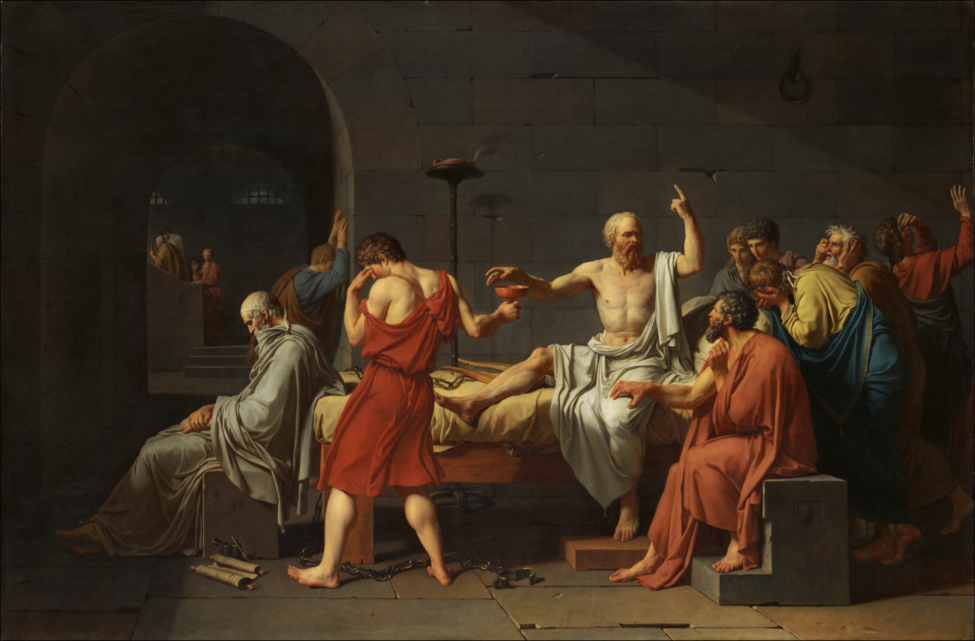

In [2]:
image_path = joinpath(@__DIR__, "..", "images", "death-of-socrates.jpg")
original = load(image_path)
original

In [3]:
image_matrix = Float64.(Gray.(original[1:4:end, 1:4:end]))
size(image_matrix)

(640, 974)

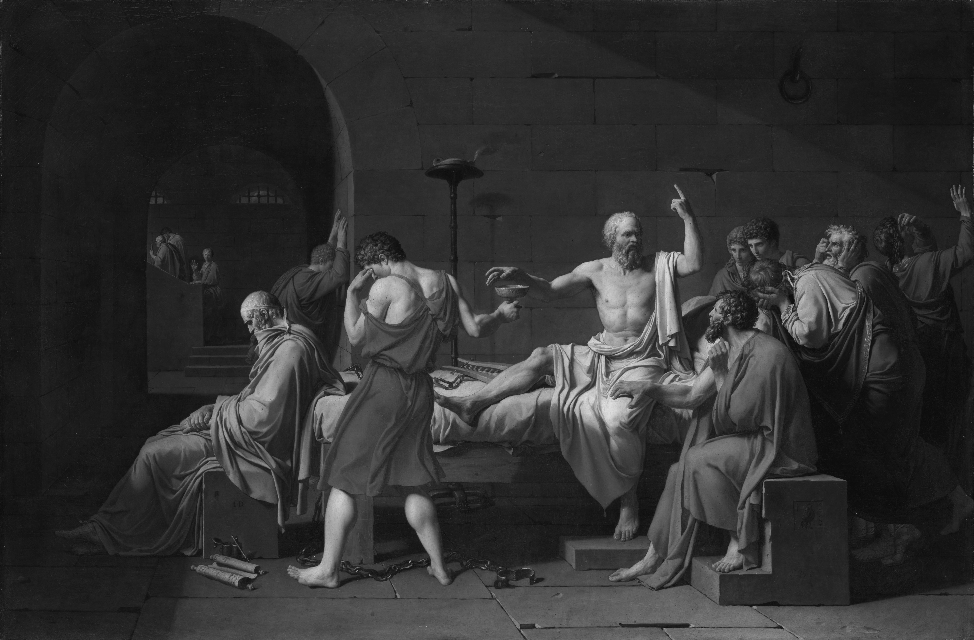

In [4]:
Gray.(image_matrix)

## 3. Compare exact and randomized approximations

The exact SVD gives the best rank-`k` approximation in Frobenius norm. We use it as a reference, then compare the randomized approximation at the same rank. Fixing a random seed makes this example reproducible.

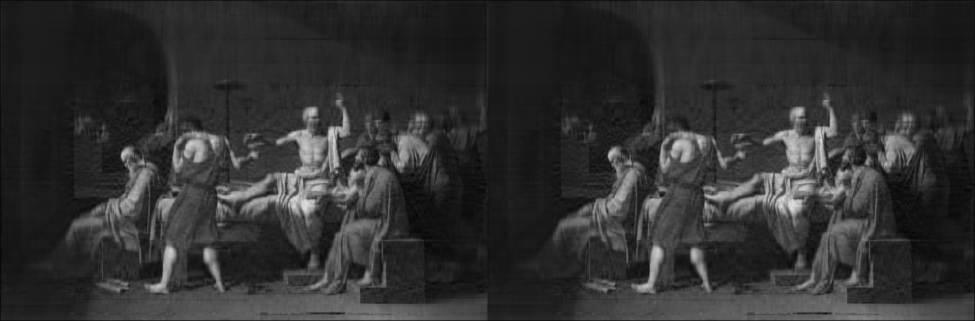

In [5]:
k = 40
oversampling = 10
power_iterations = 2

exact = svd(image_matrix; full=false)
randomized = randomized_svd(image_matrix, k;
    oversampling=oversampling,
    power_iterations=power_iterations,
    rng=MersenneTwister(2026),
)

exact_rank_k = reconstruct((U=exact.U[:, 1:k], S=exact.S[1:k], Vt=exact.Vt[1:k, :]))
randomized_rank_k = reconstruct(randomized)
Gray.(clamp.(hcat(exact_rank_k, randomized_rank_k), 0, 1))

In [6]:
exact_error = norm(image_matrix - exact_rank_k) / norm(image_matrix)
randomized_error = norm(image_matrix - randomized_rank_k) / norm(image_matrix)
(exact_relative_error=exact_error, randomized_relative_error=randomized_error, excess_error=randomized_error - exact_error)

(exact_relative_error = 0.12823635641361042, randomized_relative_error = 0.12895279850193733, excess_error = 0.0007164420883269129)

The randomized method cannot beat the exact truncated SVD's Frobenius error at the same rank, by the Eckart–Young theorem. Its goal is to get close while doing less work. The excess error above measures how far this random projection is from that optimum.

## 4. Compare computational cost

We first warm up both code paths so compilation time does not dominate. Then we time several runs and report the mean. These timings are illustrative: machine load, BLAS implementation, Julia version, matrix dimensions, target rank, and random parameters all affect the result. For small matrices, randomized overhead can make it no faster (or even slower) than exact SVD.

In [7]:
svd(image_matrix; full=false)
randomized_svd(image_matrix, k;
    oversampling=oversampling,
    power_iterations=power_iterations,
    rng=MersenneTwister(2026),
)

repeats = 3
exact_seconds = (@elapsed for _ in 1:repeats
    svd(image_matrix; full=false)
end) / repeats
randomized_seconds = (@elapsed for run in 1:repeats
    randomized_svd(image_matrix, k;
        oversampling=oversampling,
        power_iterations=power_iterations,
        rng=MersenneTwister(2026 + run),
    )
end) / repeats
(exact_seconds=exact_seconds, randomized_seconds=randomized_seconds, speedup=exact_seconds / randomized_seconds)

(exact_seconds = 0.8275269723333333, randomized_seconds = 0.038596444333333334, speedup = 21.44049760611368)

The speedup is specific to this run and problem size. Exact SVD computes all singular components, while the randomized method only computes a small projected SVD, but it still needs several passes over the matrix. Randomized methods are most useful for much larger matrices when only a modest number of components is needed.

## Your turn

1. Change `k`. How do accuracy and runtime change as you request more components?
2. Set `power_iterations = 0`, then try 1 or 3. Does the randomized error improve for this image?
3. Change `oversampling`. How much accuracy can you gain by sampling a wider subspace?
4. Repeat with another image or a larger image stride (for example `1:2:end`). At what size does the randomized method become faster on your machine?

Always compare approximations at the same target rank. Runtime alone is not enough: a useful approximation should also meet the accuracy needed for the task.